# EMA filter, explored

A single EMA (exponential moving average) stage is a first-order IIR low-pass: `y[n] = y[n-1] + alpha*(x[n] - y[n-1])`. This is the building block behind the SR860/MFLI demodulator's time-constant filter.

`alpha` isn't set directly — you set a time constant `tau` instead, and `alpha = 1 - exp(-Ts/tau)` converts it for a given sample period `Ts`. This notebook checks `ema_float.py` against the two closed-form results theory predicts: the step response and the -3dB bandwidth.

In [9]:
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from ema_float import alpha_from_tau, ema_filter, f3db

## Step response vs. the analytic `1 - exp(-t/tau)`

Feeding a unit step into a first-order low-pass should climb toward 1 following `1 - exp(-t/tau)`, same as an RC circuit charging. `Ts` and `tau` below are placeholders — swap in the real ADC rate and a representative time constant once that's settled.

alpha = 0.001


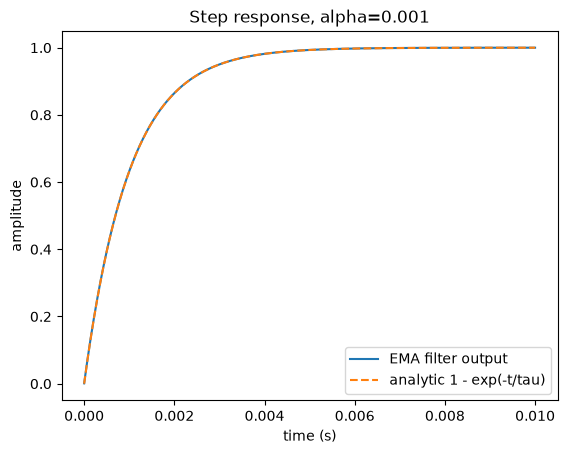

In [10]:
Ts = 1e-6   # placeholder sample period
tau = 1e-3  # placeholder time constant

alpha = alpha_from_tau(tau, Ts)
print(f'alpha = {alpha:.3g}')

n_samples = int(10 * tau / Ts)
t = np.arange(n_samples) * Ts
x = np.ones(n_samples)
y = ema_filter(x, alpha)

plt.plot(t, y, label='EMA filter output')
plt.plot(t, 1 - np.exp(-t / tau), '--', label='analytic 1 - exp(-t/tau)')
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title(f'Step response, alpha={alpha:.3g}')
plt.show()

## Frequency response vs. the theoretical -3dB point

For a single stage (`n=1`), `f3dB = sqrt(2^(1/1) - 1) / (2*pi*tau) = 1 / (2*pi*tau)`. Computing the filter's actual frequency response with `scipy.signal.freqz` and checking the magnitude at that frequency should land right on -3dB.

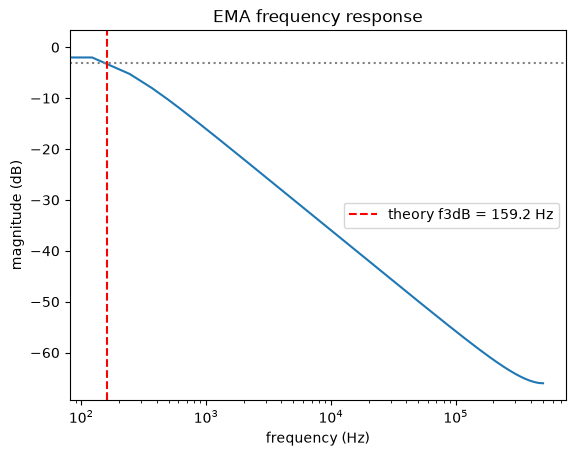

magnitude at theoretical f3dB: -3.010 dB (should be close to -3.0)


In [11]:
# y[n] = (1-alpha) y[n-1] + alpha x[n]
b, a = [alpha], [1, -(1 - alpha)]
w, h = signal.freqz(b, a, worN=4096, fs=1 / Ts)

f3db_theory = f3db(tau, n=1)
mag_at_f3db = 20 * np.log10(np.abs(signal.freqz(b, a, worN=[f3db_theory], fs=1 / Ts)[1][0]))

plt.semilogx(w, 20 * np.log10(np.abs(h)))
plt.axvline(f3db_theory, color='r', linestyle='--', label=f'theory f3dB = {f3db_theory:.1f} Hz')
plt.axhline(-3, color='gray', linestyle=':')
plt.xlabel('frequency (Hz)')
plt.ylabel('magnitude (dB)')
plt.legend()
plt.title('EMA frequency response')
plt.show()

print(f'magnitude at theoretical f3dB: {mag_at_f3db:.3f} dB (should be close to -3.0)')

## Two-tone example: separating 10 Hz from 100 Hz

Same idea as before, just shifted up by 10x (still one decade of separation, so the same tradeoff shape repeats, with `tau` shrinking by 10x to match):

| f3dB | tau | attenuation @10Hz | attenuation @100Hz |
|---|---|---|---|
| 5 Hz | 31.8 ms | -6.99 dB | -26.0 dB |
| 10 Hz | 15.9 ms | -3.01 dB | -20.0 dB |
| 20 Hz | 8.0 ms | -0.97 dB | -14.2 dB |
| 30 Hz | 5.3 ms | -0.46 dB | -10.8 dB |
| 50 Hz | 3.2 ms | -0.17 dB | -7.0 dB |

Picking `f3dB = 20 Hz` as a middle-ground: 10 Hz comes through almost untouched (-1 dB) while 100 Hz is knocked down by about -14 dB (~20% of its original amplitude).

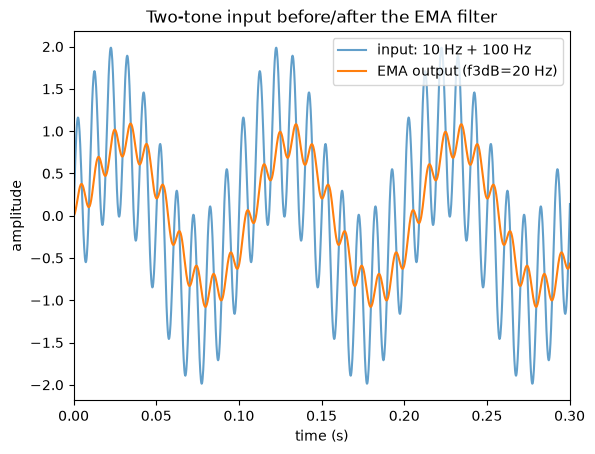

In [12]:
Fs = 5000.0          # demo sample rate, independent of the real ADC rate (still unanswered)
duration = 1.0       # 1 Hz FFT resolution so the 10/100 Hz tones land on exact bins
t_demo = np.arange(0, duration, 1 / Fs)
x_tone = np.sin(2 * np.pi * 10 * t_demo) + np.sin(2 * np.pi * 100 * t_demo)

f3db_choice = 20.0   # the middle-ground pick from the table above
tau_choice = 1 / (2 * np.pi * f3db_choice)
alpha_choice = alpha_from_tau(tau_choice, 1 / Fs)
y_tone = ema_filter(x_tone, alpha_choice)

plt.plot(t_demo, x_tone, label='input: 10 Hz + 100 Hz', alpha=0.7)
plt.plot(t_demo, y_tone, label=f'EMA output (f3dB={f3db_choice:.0f} Hz)')
plt.xlim(0, 0.3)
plt.xlabel('time (s)')
plt.ylabel('amplitude')
plt.legend()
plt.title('Two-tone input before/after the EMA filter')
plt.show()

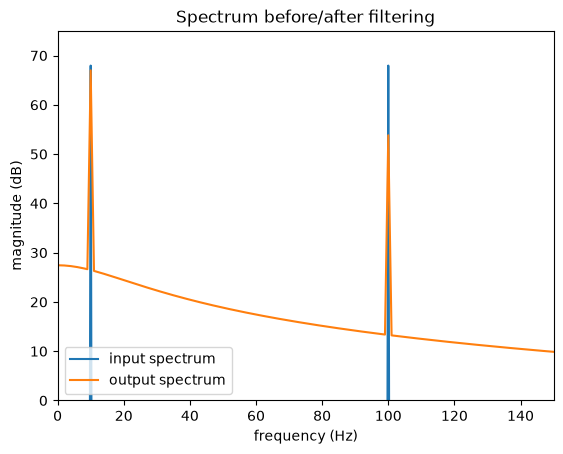

 10 Hz: measured attenuation =  -0.97 dB, theory =  -0.97 dB
100 Hz: measured attenuation = -14.14 dB, theory = -14.15 dB


In [13]:
X = np.fft.rfft(x_tone)
Y = np.fft.rfft(y_tone)
freqs = np.fft.rfftfreq(len(x_tone), d=1 / Fs)

plt.plot(freqs, 20 * np.log10(np.abs(X) + 1e-12), label='input spectrum')
plt.plot(freqs, 20 * np.log10(np.abs(Y) + 1e-12), label='output spectrum')
plt.xlim(0, 150)
plt.ylim(0, 75)  # zoom in: the other bins are ~floating-point zero (-200+ dB),
                 # which would otherwise squash the real peaks into the top sliver
plt.xlabel('frequency (Hz)')
plt.ylabel('magnitude (dB)')
plt.legend()
plt.title('Spectrum before/after filtering')
plt.show()

for f in [10, 100]:
    k = int(round(f * duration))
    measured_db = 20 * np.log10(np.abs(Y[k]) / np.abs(X[k]))
    theory_db = -10 * np.log10(1 + (f / f3db_choice) ** 2)
    print(f'{f:>3} Hz: measured attenuation = {measured_db:6.2f} dB, theory = {theory_db:6.2f} dB')

The measured attenuation from the FFT should match the closed-form theory number closely — confirming the roll-off formula holds for an actual two-tone signal, not just a single swept sinusoid.